# Phase 2 – Part A: Unsupervised Learning
**SW485-Project-Group3 — Diabetes Screening & Triage Decision-Support System**

| Section | Owner |
|---|---|
| 1. Clustering Rationale & Algorithm Selection | Deema (K-Means) + Dalia (GMM) |
| 2. Data Preparation (target removal, feature scaling) | Deema |
| 3. Cluster Determination & Implementation – K-Means | Deema |
| 4. Cluster Determination & Implementation – GMM | Dalia |
| 5. Evaluation Metrics & Comparison | Dalia |
| 6. Cluster Interpretation & Profiles | Dalia |
| 7. Integration Strategy | Deema |
| 8. Challenges & Limitations | Both |

## 1. Clustering Rationale & Algorithm Selection

### 1.1 K-Means (Deema)
- **Dataset size:** ~70,000 rows × 21 features — K-Means scales linearly with the number of rows, so it runs on the full dataset.
- **Feature types:** mostly binary (0/1) and ordinal health indicators, all numeric after Phase 1 preprocessing and standardised here.
- **Expected cluster shapes:** assumes roughly spherical, similar-size groups — a reasonable first assumption for broad patient risk profiles.
- **Interpretability:** each cluster is summarised by its centroid (average patient), which is easy to explain to decision-makers.
- **Integration:** a fitted model can assign any new patient to a cluster with `predict()`, which the dashboard needs.
- **Known caveat:** K-Means uses Euclidean distance and assumes continuous features, while most features here are binary (`HighBP`, `Smoker`, `HighChol`, …).
  On 0/1 data the distance only counts mismatches, and centroids become proportions (e.g. "70% have HighBP"), not real patients.
  We accept this because the centroids are still interpretable as risk proportions; categorical alternatives (K-Modes / K-Prototypes) are discussed in the Limitations.

### 1.2 Gaussian Mixture Model (Dalia)
- **Why a second, different algorithm:** GMM is a *probabilistic* (model-based) method, while K-Means is distance-based. Comparing the two shows whether the risk groups found by K-Means are stable or depend on the algorithm.
- **Soft membership:** GMM gives each patient a probability of belonging to every cluster (e.g. 70% moderate / 30% high risk). For a triage system this is useful in principle: borderline patients can be flagged instead of being forced into one group.
- **Flexible cluster shapes:** each component has its own covariance matrix, so clusters can be elliptical and of different sizes — K-Means can only find roughly spherical, similar-size groups.
- **Choosing k:** GMM is a statistical model, so the number of components can be selected with the **BIC** (Bayesian Information Criterion), which rewards fit but penalises complexity.
- **Dataset size & scalability:** EM training is more expensive than K-Means, but at ~55,000 rows × 21 features it still runs in seconds.
- **Integration:** like K-Means, a fitted GMM has `predict()` / `predict_proba()`, so it can assign new patients in the dashboard.
- **Known caveat:** GMM assumes each cluster is a continuous Gaussian distribution. Most features here are binary (0/1), which breaks this assumption — Section 4 shows the effect this has in practice.

## 2. Data Preparation
### 2.1 Imports & shared settings
> ⚠️ Shared cell: Dalia must use exactly the same settings so both algorithms are compared on identical data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score

RANDOM_STATE = 42        # same seed for every algorithm
EVAL_SAMPLE  = 10_000    # sample size for Silhouette (too slow on all 70k rows)
TSNE_SAMPLE  = 5_000     # sample size for t-SNE
TARGET       = "Diabetes_binary"

np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")

### 2.2 Load the shared train/test split from Phase 1
We reuse the **same** split created in Phase 1 (`train_data.csv` / `test_data.csv`: duplicates removed, BMI outliers capped, no SMOTE),
so the integration experiment in Section 7 is a fair before/after comparison with the Phase 1 results.
The **unscaled** files are used because Phase 1 scaled only the non-binary columns; here all features are standardised for clustering (Section 2.4).

In [2]:
train_df = pd.read_csv("../Dataset/train_data.csv")
test_df  = pd.read_csv("../Dataset/test_data.csv")
print("Train:", train_df.shape, "| Test:", test_df.shape)
train_df.head()

Train: (55245, 22) | Test: (13812, 22)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1.0,1.0,1.0,40.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,4.0,21.0,14.0,0.0,0.0,7.0,5.0,7.0,1.0
1,1.0,1.0,1.0,47.0,1.0,0.0,1.0,0.0,1.0,1.0,...,1.0,3.0,30.0,14.0,1.0,0.0,6.0,3.0,1.0,1.0
2,0.0,0.0,1.0,24.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,2.0,3.0,0.0,0.0,0.0,7.0,5.0,7.0,0.0
3,1.0,1.0,1.0,42.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,3.0,0.0,0.0,0.0,0.0,9.0,5.0,7.0,1.0
4,0.0,0.0,1.0,35.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,3.0,6.0,0.0,1.0,0.0,9.0,5.0,6.0,1.0


### 2.3 Remove the class label
The target is removed **before** clustering (as required), so clusters are formed only from patient features.
It is kept separately and used **only** for external validation (BCubed), diabetes rates per cluster, and the integration experiment.
Clustering models are fitted on the **train split only**.

In [3]:
y_train = train_df[TARGET].astype(int).values
y_test  = test_df[TARGET].astype(int).values
X_train = train_df.drop(columns=[TARGET])
X_test  = test_df.drop(columns=[TARGET])

feature_names = X_train.columns.tolist()
print("Features used for clustering:", len(feature_names))
print("Train class balance:", y_train.mean().round(3))

Features used for clustering: 21
Train class balance: 0.508


### 2.4 Feature scaling
K-Means and GMM are distance/variance based, so features with larger ranges (e.g. `BMI`, `Age`, `MentHlth`) would dominate binary ones.
`StandardScaler` puts every feature on the same scale (mean 0, std 1) so each contributes fairly.

In Phase 1 only the non-binary columns were scaled (Logistic Regression needed it; tree models did not).
For clustering **all 21 features** are standardised, so binary features carry the same weight as `BMI` or `Age` in the distance.
The scaler is fitted on the **train split only**.

In [4]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
print("Train mean ≈ 0:", np.allclose(X_train_s.mean(axis=0), 0, atol=1e-6))

Train mean ≈ 0: True


### 2.5 Fixed evaluation samples (shared)
Taken from the train split, stratified on the target so the samples keep the 50/50 class balance.

In [5]:
idx_train = np.arange(len(X_train_s))
idx_eval, _ = train_test_split(idx_train, train_size=EVAL_SAMPLE,
                               stratify=y_train, random_state=RANDOM_STATE)
idx_tsne, _ = train_test_split(idx_eval, train_size=TSNE_SAMPLE,
                               stratify=y_train[idx_eval], random_state=RANDOM_STATE)

X_eval, y_eval = X_train_s[idx_eval], y_train[idx_eval]
X_tsne_in      = X_train_s[idx_tsne]
print(X_eval.shape, X_tsne_in.shape, "| class balance:", y_eval.mean().round(3))

(10000, 21) (5000, 21) | class balance: 0.508


### 2.6 Shared evaluation function (used for BOTH algorithms)
One function computes every metric the same way, so the comparison table in Section 5 is fair.
- **WCSS** is computed manually (sum of squared distances from each point to the mean of its own cluster), because `GaussianMixture` has no `inertia_`.
- **Silhouette** and **Davies-Bouldin** are computed on the fixed 10,000-row sample.
- **BCubed Precision/Recall** use `Diabetes_binary` as external ground truth.

In [6]:
def wcss_manual(X, labels):
    """Within-cluster sum of squares from hard labels — works for any algorithm."""
    return float(sum(((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum()
                     for c in np.unique(labels)))

def bcubed(labels, y):
    """BCubed precision, recall and F1 (computed from the cluster × class contingency table)."""
    ct = pd.crosstab(labels, y).values.astype(float)
    n = ct.sum()
    precision = (ct ** 2 / ct.sum(axis=1, keepdims=True)).sum() / n
    recall    = (ct ** 2 / ct.sum(axis=0, keepdims=True)).sum() / n
    return precision, recall, 2 * precision * recall / (precision + recall)

def evaluate_clustering(name, train_labels):
    """train_labels: cluster label for every row of X_train_s."""
    lab_eval = train_labels[idx_eval]
    p, r, f = bcubed(train_labels, y_train)
    return {"Algorithm": name,
            "k": len(np.unique(train_labels)),
            "WCSS": wcss_manual(X_train_s, train_labels),
            "Silhouette (↑)": silhouette_score(X_eval, lab_eval),
            "Davies-Bouldin (↓)": davies_bouldin_score(X_eval, lab_eval),
            "BCubed Precision": p, "BCubed Recall": r, "BCubed F1": f}

results = {}   # each algorithm adds its row here → comparison table in Section 5

### 2.7 Shared 2D projections (reused by both algorithms)

In [7]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_eval_pca = pca.fit_transform(X_eval)
print("Variance explained by 2 PCs:", pca.explained_variance_ratio_.sum().round(3))

tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE)
X_tsne_2d = tsne.fit_transform(X_tsne_in)   # takes ~1-2 minutes

Variance explained by 2 PCs: 0.25


## 3. K-Means (Deema)
### 3.1 Determining the optimal number of clusters

k= 2 | WCSS=1,023,812 | Silhouette=0.1562
k= 3 | WCSS=967,989 | Silhouette=0.0728
k= 4 | WCSS=916,488 | Silhouette=0.0794
k= 5 | WCSS=870,166 | Silhouette=0.0859
k= 6 | WCSS=851,782 | Silhouette=0.0753
k= 7 | WCSS=799,753 | Silhouette=0.0921
k= 8 | WCSS=776,825 | Silhouette=0.0836
k= 9 | WCSS=737,924 | Silhouette=0.0928
k=10 | WCSS=714,483 | Silhouette=0.0939


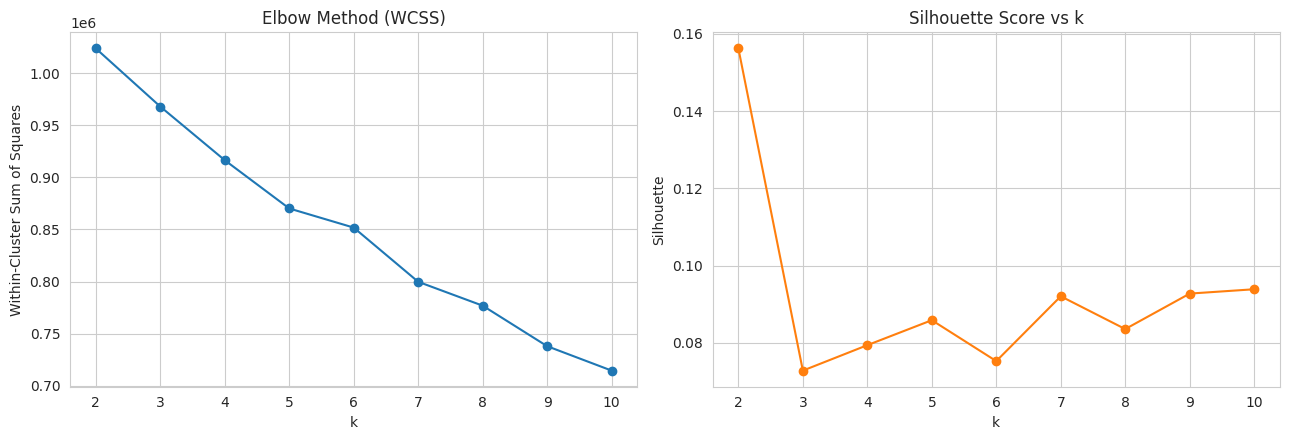

In [8]:
k_range = range(2, 11)
wcss, sil = [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    km.fit(X_train_s)                                  # fitted on the train split
    wcss.append(km.inertia_)
    sil.append(silhouette_score(X_eval, km.predict(X_eval)))   # Silhouette on the sample
    print(f"k={k:2d} | WCSS={km.inertia_:,.0f} | Silhouette={sil[-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(list(k_range), wcss, "o-")
ax[0].set(title="Elbow Method (WCSS)", xlabel="k", ylabel="Within-Cluster Sum of Squares")
ax[1].plot(list(k_range), sil, "o-", color="tab:orange")
ax[1].set(title="Silhouette Score vs k", xlabel="k", ylabel="Silhouette")
plt.tight_layout(); plt.show()

**Choice of k = 3.**
- **Elbow:** WCSS decreases steadily with no sharp elbow, which is expected for mostly binary features — the elbow alone cannot decide k.
- **Silhouette:** k = 2 has the highest score (0.156); for k ≥ 3 the scores are all low and similar (0.07–0.09), so no larger k is clearly better.
- **Domain meaning (deciding factor):** k = 2 only separates "healthy" vs "unhealthy" patients. k = 3 gives three clearly different risk groups low (20% diabetic), moderate (63%: high blood pressure and cholesterol, older, but fair general health) and high (76%: poor general health, difficulty walking, many days of poor physical health). This matches a triage system with low / medium / high priority. k = 4 and k = 5 keep the same three groups and only add very small clusters (3–5% of patients) with no new meaning.
- Therefore k = 3 is chosen as the best trade-off between cluster quality and interpretability for the decision-support system.


In [9]:
BEST_K = 3  #chosen based on the analysis above

kmeans = KMeans(n_clusters=BEST_K, n_init=10, random_state=RANDOM_STATE)
km_labels = kmeans.fit_predict(X_train_s)
km_labels_eval = km_labels[idx_eval]

results["K-Means"] = evaluate_clustering("K-Means", km_labels)
pd.Series(results["K-Means"])

,0
Algorithm,K-Means
k,3
WCSS,967988.745456
Silhouette (↑),0.072813
Davies-Bouldin (↓),2.94059
BCubed Precision,0.608933
BCubed Recall,0.421793
BCubed F1,0.498374


### 3.2 Visualising K-Means clusters (PCA & t-SNE)

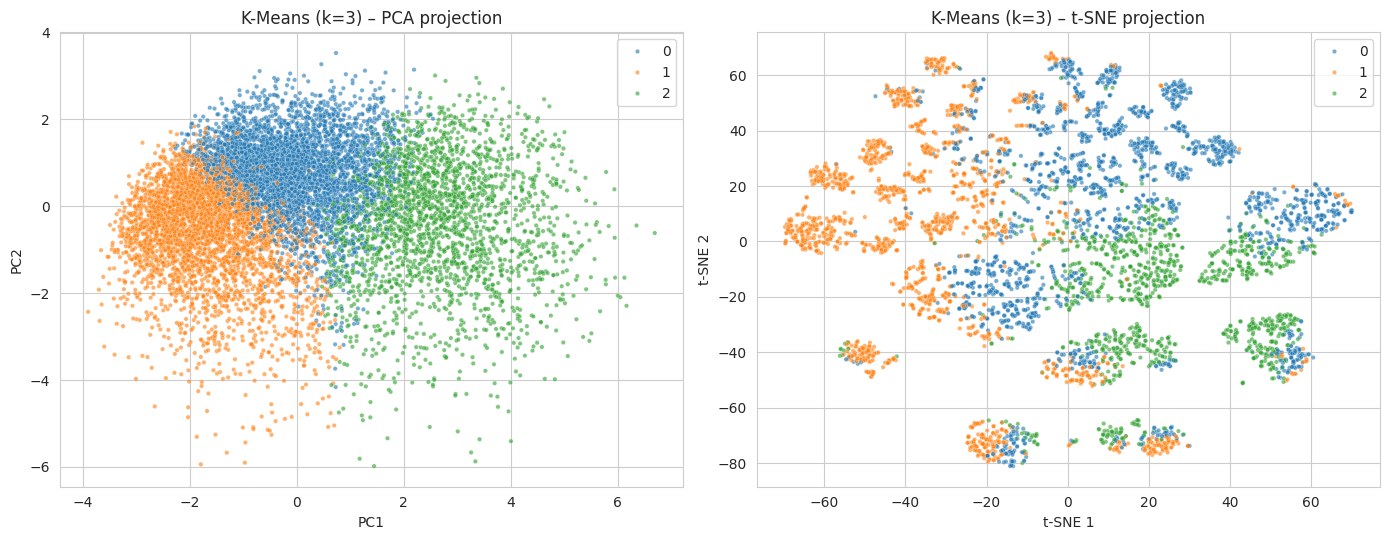

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(x=X_eval_pca[:, 0], y=X_eval_pca[:, 1], hue=km_labels_eval,
                palette="tab10", s=10, alpha=0.6, ax=ax[0], legend="full")
ax[0].set(title=f"K-Means (k={BEST_K}) – PCA projection", xlabel="PC1", ylabel="PC2")

sns.scatterplot(x=X_tsne_2d[:, 0], y=X_tsne_2d[:, 1], hue=km_labels[idx_tsne],
                palette="tab10", s=10, alpha=0.6, ax=ax[1], legend="full")
ax[1].set(title=f"K-Means (k={BEST_K}) – t-SNE projection", xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout(); plt.show()

### 3.3 Cluster size distribution

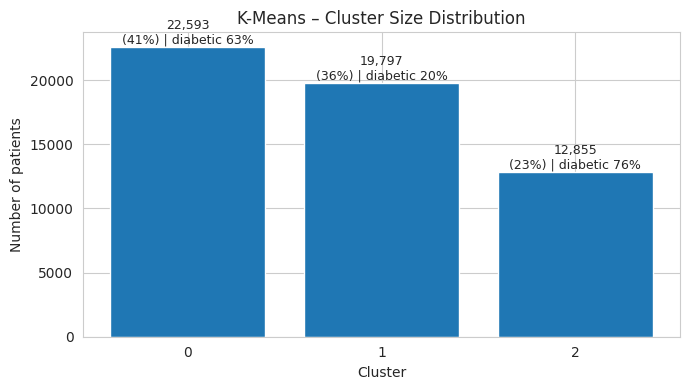

In [11]:
sizes = pd.Series(km_labels).value_counts().sort_index()
diab_rate = pd.Series(y_train).groupby(km_labels).mean()

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(sizes.index.astype(str), sizes.values)
for b, n, r in zip(bars, sizes.values, diab_rate.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height(),
            f"{n:,}\n({n/len(km_labels):.0%}) | diabetic {r:.0%}", ha="center", va="bottom", fontsize=9)
ax.set(title="K-Means – Cluster Size Distribution", xlabel="Cluster", ylabel="Number of patients")
plt.tight_layout(); plt.show()

**Observations (K-Means, k = 3):**
- **Cluster sizes are reasonably balanced** (41% / 36% / 23%), so no cluster is too small to be useful.
- **Diabetes rate differs clearly between clusters** even though the label was not used for clustering:
  - Cluster 1 — **low risk** (36% of patients, 20% diabetic)
  - Cluster 0 — **moderate risk** (41% of patients, 63% diabetic)
  - Cluster 2 — **high risk** (23% of patients, 76% diabetic)
- **PCA plot:** the three clusters lie in order along PC1 (low → moderate → high risk), with overlapping boundaries. The first two components explain only 25% of the variance, so the overlap is partly due to the 2D projection.
- **t-SNE plot:** points form many small islands, because binary features produce many identical patient profiles. Most islands are dominated by one cluster, but some contain mixed colours, confirming that the groups are not sharply separated.
- **Metrics:** Silhouette (0.073) is low and Davies-Bouldin (2.94) is high, meaning the clusters overlap — expected for mostly binary health data. BCubed Precision (0.61) shows clusters are moderately "pure" with respect to diabetes status; BCubed Recall (0.42) is lower because each class is spread over more than one cluster (3 clusters vs 2 classes).
- **Conclusion:** the clusters are not geometrically well separated, but they are **meaningful for the domain**: they form clear low / moderate / high risk groups that can support triage decisions.

## 4. Gaussian Mixture Model (Dalia)
### 4.1 Determining the number of components (BIC)
GMM is fitted on the same scaled train split (`X_train_s`) for k = 2…10, with two covariance types:
- `full`: every component has its own full covariance matrix (most flexible).
- `diag`: only per-feature variances (fewer parameters, faster).

`reg_covar=1e-4` adds a small value to the covariance diagonal. Without it, GMM fails on binary features, because a cluster where a feature is always 0 has zero variance (singular covariance matrix).


full | k= 2 | BIC=   2,599,277 | Silhouette=0.2282
full | k= 3 | BIC=   1,214,482 | Silhouette=0.1844
full | k= 4 | BIC=     884,853 | Silhouette=0.1401
full | k= 5 | BIC=     501,257 | Silhouette=0.1481
full | k= 6 | BIC=     373,868 | Silhouette=0.0594
full | k= 7 | BIC=     244,086 | Silhouette=0.0434
full | k= 8 | BIC=     129,241 | Silhouette=0.0590
full | k= 9 | BIC=     268,207 | Silhouette=0.0693
full | k=10 | BIC=    -203,367 | Silhouette=0.0889
diag | k= 2 | BIC=   2,745,471 | Silhouette=0.2282
diag | k= 3 | BIC=   1,345,279 | Silhouette=0.1844
diag | k= 4 | BIC=     927,468 | Silhouette=0.1368
diag | k= 5 | BIC=     858,627 | Silhouette=0.1388
diag | k= 6 | BIC=     644,925 | Silhouette=0.0383
diag | k= 7 | BIC=     308,615 | Silhouette=0.0446
diag | k= 8 | BIC=     187,880 | Silhouette=0.0600
diag | k= 9 | BIC=     251,049 | Silhouette=0.0704
diag | k=10 | BIC=     -83,896 | Silhouette=0.0812


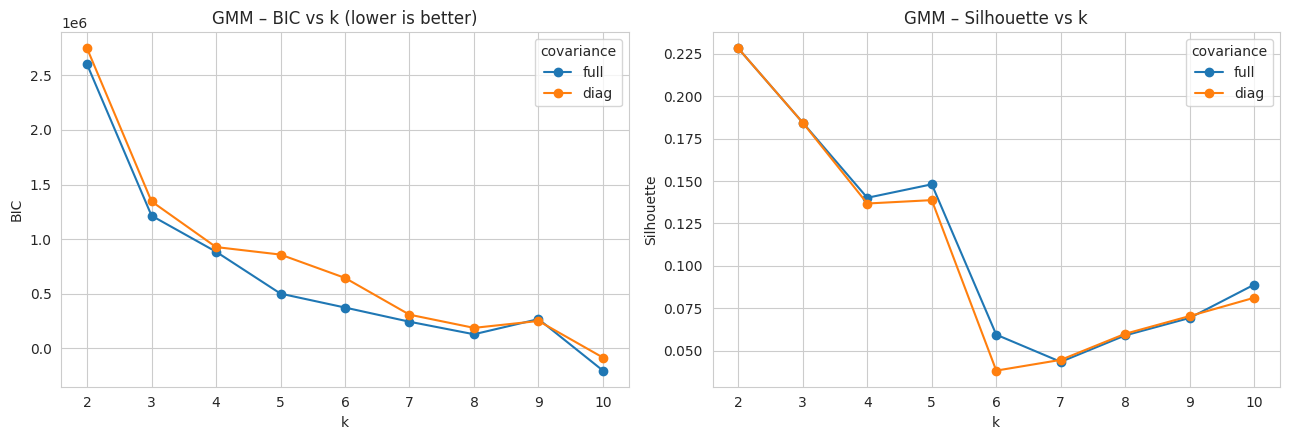

In [12]:
gmm_k_range = range(2, 11)
bic_scores = {"full": [], "diag": []}
gmm_sil = {"full": [], "diag": []}

for cov in ["full", "diag"]:
    for k in gmm_k_range:
        g = GaussianMixture(n_components=k, covariance_type=cov,
                            reg_covar=1e-4, random_state=RANDOM_STATE)
        g.fit(X_train_s)                                       # fitted on the train split
        bic_scores[cov].append(g.bic(X_train_s))
        gmm_sil[cov].append(silhouette_score(X_eval, g.predict(X_eval)))
        print(f"{cov:4s} | k={k:2d} | BIC={bic_scores[cov][-1]:>12,.0f} | Silhouette={gmm_sil[cov][-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for cov in ["full", "diag"]:
    ax[0].plot(list(gmm_k_range), bic_scores[cov], "o-", label=cov)
    ax[1].plot(list(gmm_k_range), gmm_sil[cov], "o-", label=cov)
ax[0].set(title="GMM – BIC vs k (lower is better)", xlabel="k", ylabel="BIC")
ax[1].set(title="GMM – Silhouette vs k", xlabel="k", ylabel="Silhouette")
ax[0].legend(title="covariance"); ax[1].legend(title="covariance")
plt.tight_layout(); plt.show()

**Choice of k = 3 (full covariance).**
- **BIC never reaches a minimum:** it keeps decreasing until k = 10 and even becomes negative. On binary data, GMM can keep increasing the likelihood by creating components in which a binary feature is constant (variance ≈ 0), so the BIC rewards splitting the data more and more. **BIC alone cannot choose k here.**
- **Largest improvement:** the biggest drop in BIC happens from k = 2 to k = 3; after that the curve flattens.
- **`full` vs `diag`:** both give almost identical Silhouette values; `full` has a lower BIC, so it is kept.
- **Silhouette** is highest at k = 2, but k = 2 puts 96% of patients in one cluster, which is useless for decision support.
- **Decision:** k = 3, which is also the **same k as K-Means**, so the comparison in Section 5 is fair (same number of groups, different algorithm).


### 4.2 Final GMM model


In [13]:
GMM_K = 3
gmm = GaussianMixture(n_components=GMM_K, covariance_type="full",
                      reg_covar=1e-4, random_state=RANDOM_STATE)
gmm.fit(X_train_s)
gmm_labels = gmm.predict(X_train_s)          # hard label = most likely component
gmm_labels_eval = gmm_labels[idx_eval]

results["GMM"] = evaluate_clustering("GMM", gmm_labels)
pd.Series(results["GMM"])


,0
Algorithm,GMM
k,3
WCSS,1067889.65996
Silhouette (↑),0.184398
Davies-Bouldin (↓),3.149475
BCubed Precision,0.512514
BCubed Recall,0.696404
BCubed F1,0.590473


### 4.3 Why do the GMM clusters look like this?
Two checks: (1) how "soft" the memberships really are, and (2) which binary features are **constant** inside each cluster.

In [14]:
gmm_sizes = pd.Series(gmm_labels).value_counts(normalize=True).sort_index()
gmm_diab  = pd.Series(y_train).groupby(gmm_labels).mean()
max_prob  = gmm.predict_proba(X_train_s).max(axis=1)

print(pd.DataFrame({"size %": (gmm_sizes * 100).round(1),
                    "diabetic %": (gmm_diab * 100).round(1)}))
print(f"\nAverage highest membership probability: {max_prob.mean():.4f}")
print(f"Patients with max probability < 0.9:    {(max_prob < 0.9).mean():.2%}\n")

for c in range(GMM_K):
    const = [f for f in feature_names if X_train[gmm_labels == c][f].nunique() == 1]
    print(f"Cluster {c}: constant features → {const}")

   size %  diabetic %
0    11.3        31.1
1     6.4        66.6
2    82.2        52.3

Average highest membership probability: 1.0000
Patients with max probability < 0.9:    0.00%

Cluster 0: constant features → ['Stroke', 'HeartDiseaseorAttack', 'DiffWalk']
Cluster 1: constant features → []
Cluster 2: constant features → ['CholCheck', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost']


**What this shows:**
- **Very unbalanced clusters:** one cluster holds 82% of the patients, while the other two are small (11% and 6%). K-Means gave 36% / 41% / 23%.
- **Membership is not really "soft":** the average highest probability is 1.0 and no patient has a probability below 0.9, so every patient is assigned with full certainty. The main advantage of GMM is lost on this data.
- **Clusters are defined by constant binary features, not by overall risk:** Cluster 0 contains only patients with no stroke, no heart disease and no difficulty walking (all = 0). Cluster 2 contains only patients who all had a cholesterol check, have healthcare coverage, no heavy drinking and no cost barrier. A Gaussian with almost zero variance on a 0/1 feature gives a very high likelihood, so GMM prefers these "pure" splits. This also explains why the BIC kept decreasing.
- **Diabetes rates are less separated** than with K-Means (31% / 52% / 67% vs 20% / 63% / 76%).


### 4.4 Visualising GMM clusters (same PCA & t-SNE projections as K-Means)

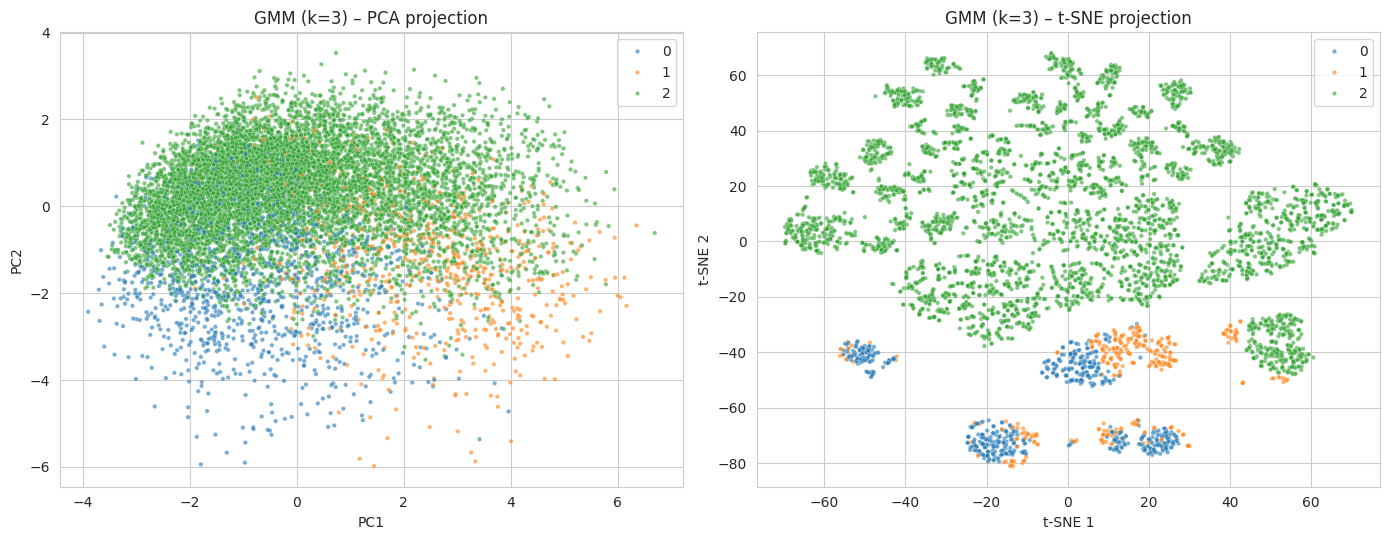

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(x=X_eval_pca[:, 0], y=X_eval_pca[:, 1], hue=gmm_labels_eval,
                palette="tab10", s=10, alpha=0.6, ax=ax[0], legend="full")
ax[0].set(title=f"GMM (k={GMM_K}) – PCA projection", xlabel="PC1", ylabel="PC2")

sns.scatterplot(x=X_tsne_2d[:, 0], y=X_tsne_2d[:, 1], hue=gmm_labels[idx_tsne],
                palette="tab10", s=10, alpha=0.6, ax=ax[1], legend="full")
ax[1].set(title=f"GMM (k={GMM_K}) – t-SNE projection", xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout(); plt.show()

**Observations:**
- **PCA:** the large GMM cluster (2, 82%) covers most of the space, while the two small clusters sit at the bottom edge: cluster 0 on the left and cluster 1 on the right. GMM separates them mainly along **PC2**, whereas K-Means arranged its three clusters along **PC1** from low to high risk.
- **t-SNE:** cluster 2 covers almost all the upper "islands", while clusters 0 and 1 are confined to a few small islands at the bottom and are mixed inside the same islands. These islands are groups of patients with identical binary values, which confirms that GMM splits patients by binary feature combinations rather than by overall risk level.

## 5. Evaluation Metrics & Comparison (Dalia)

In [16]:
comparison = pd.DataFrame(results.values()).set_index("Algorithm").round(4)
comparison

,k,WCSS,Silhouette (↑),Davies-Bouldin (↓),BCubed Precision,BCubed Recall,BCubed F1
Algorithm,,,,,,,
K-Means,3,9.679887e+05,0.0728,2.9406,0.6089,0.4218,0.4984
GMM,3,1.067890e+06,0.1844,3.1495,0.5125,0.6964,0.5905


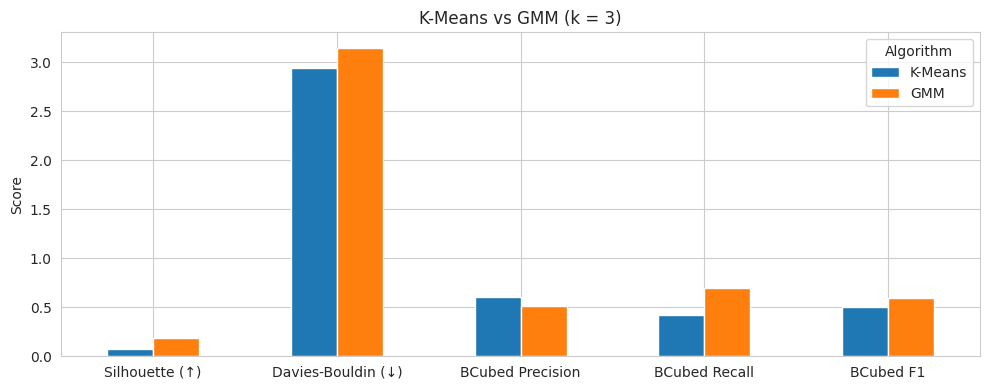

,K-Means size %,K-Means diabetic %,GMM size %,GMM diabetic %
0,40.9,63.4,11.3,31.1
1,35.8,20.3,6.4,66.6
2,23.3,75.8,82.2,52.3


In [17]:
metrics = ["Silhouette (↑)", "Davies-Bouldin (↓)", "BCubed Precision", "BCubed Recall", "BCubed F1"]
fig, ax = plt.subplots(figsize=(10, 4))
comparison[metrics].T.plot(kind="bar", ax=ax, rot=0)
ax.set(title="K-Means vs GMM (k = 3)", ylabel="Score")
plt.tight_layout(); plt.show()

side = pd.DataFrame({
    "K-Means size %":     (pd.Series(km_labels).value_counts(normalize=True).sort_index() * 100).round(1),
    "K-Means diabetic %": (pd.Series(y_train).groupby(km_labels).mean() * 100).round(1),
    "GMM size %":         (pd.Series(gmm_labels).value_counts(normalize=True).sort_index() * 100).round(1),
    "GMM diabetic %":     (pd.Series(y_train).groupby(gmm_labels).mean() * 100).round(1)})
side

**Reading the table:**

| Metric | Better | Winner | Why |
|---|---|---|---|
| WCSS | lower | **K-Means** | K-Means directly minimises WCSS, so this is expected |
| Silhouette | higher | GMM (0.18 vs 0.07) | misleading: one GMM cluster holds 82% of patients, and a huge cluster with two small "pure" ones gives a higher Silhouette |
| Davies-Bouldin | lower | **K-Means** (2.94 vs 3.15) | K-Means clusters are more compact relative to their separation |
| BCubed Precision | higher | **K-Means** (0.61 vs 0.51) | K-Means clusters are purer with respect to diabetes status |
| BCubed Recall | higher | GMM (0.70 vs 0.42) | misleading: most patients of each class fall into the same giant cluster; a single cluster would give recall = 1.0 |

### Final algorithm choice: **K-Means (k = 3)** (decided together)
1. **Domain meaning:** K-Means gives three clear risk levels (20% / 63% / 76% diabetic) that map directly to low / medium / high triage priority. GMM groups patients by which binary features are constant, which is hard to explain to decision-makers.
2. **Balanced, usable segments:** 36% / 41% / 23% vs 82% / 11% / 6%. A segment containing 82% of patients gives the dashboard almost no information.
3. **Purity:** higher BCubed Precision and lower Davies-Bouldin. GMM's better Silhouette and Recall are both side-effects of the giant cluster.
4. **GMM's advantage disappears:** soft membership was the main reason to use GMM, but all probabilities are ≈ 1.0 on this data.
5. **Deployment:** K-Means is simpler and faster, and each cluster is summarised by one centroid that is easy to explain.
6. **The giant GMM cluster is uninformative:** its diabetes rate (52%) is almost the same as the overall rate (51%), so assigning a patient to it says almost nothing about their risk.

## 6. Cluster Interpretation & Profiles (Dalia)
### 6.1 Profiling function
`profile_clusters()` works on **any** label array, so it was run on both algorithms before the final decision. It uses the **unscaled** `X_train`, so values are readable (binary features → share of patients, `BMI`/`Age`/`GenHlth` → averages).
- **Mean per cluster vs overall mean.**
- **Feature importance per cluster:** the standardised difference `(cluster mean − overall mean) / overall std`. A large positive or negative value means the feature strongly distinguishes that cluster from the average patient.

In [18]:
def profile_clusters(labels, name=""):
    labels = np.asarray(labels)
    means   = X_train.groupby(labels).mean().T             # features × clusters
    overall = X_train.mean()
    importance = means.sub(overall, axis=0).div(X_train.std(), axis=0)

    summary = pd.DataFrame({
        "size":       pd.Series(labels).value_counts().sort_index(),
        "size %":     (pd.Series(labels).value_counts(normalize=True).sort_index() * 100).round(1),
        "diabetic %": (pd.Series(y_train).groupby(labels).mean() * 100).round(1)})
    print(f"=== {name} ===")
    display(summary)
    return {"summary": summary, "means": means.assign(overall=overall), "importance": importance}

gmm_profile = profile_clusters(gmm_labels, "GMM")
km_profile  = profile_clusters(km_labels,  "K-Means")

=== GMM ===


,size,size %,diabetic %
0,6267,11.3,31.1
1,3542,6.4,66.6
2,45436,82.2,52.3


=== K-Means ===


,size,size %,diabetic %
0,22593,40.9,63.4
1,19797,35.8,20.3
2,12855,23.3,75.8


### 6.2 Ordering the K-Means clusters by risk
K-Means numbers clusters arbitrarily (here 1 = low, 0 = moderate, 2 = high risk). The clusters are renamed by their diabetes rate so the labels are **stable and meaningful** for the GenAI prompts and the dashboard.

In [19]:
risk_order = km_profile["summary"]["diabetic %"].sort_values().index.tolist()   # low → high
RISK_NAMES = dict(zip(risk_order, ["Low risk", "Moderate risk", "High risk"]))
print("K-Means cluster ID → risk segment:", RISK_NAMES)

km_means = km_profile["means"].rename(columns=RISK_NAMES)[["Low risk", "Moderate risk", "High risk", "overall"]]
km_means.round(2)

K-Means cluster ID → risk segment: {1: 'Low risk', 0: 'Moderate risk', 2: 'High risk'}


,Low risk,Moderate risk,High risk,overall
HighBP,0.09,0.88,0.77,0.57
HighChol,0.24,0.70,0.70,0.53
CholCheck,0.94,1.00,0.99,0.97
BMI,27.34,30.33,32.94,29.87
Smoker,0.36,0.52,0.60,0.48
Stroke,0.01,0.05,0.17,0.06
HeartDiseaseorAttack,0.01,0.17,0.32,0.15
PhysActivity,0.84,0.72,0.42,0.70
Fruits,0.65,0.61,0.53,0.60
Veggies,0.85,0.78,0.68,0.78


### 6.3 Feature importance per cluster
Red = higher than the average patient, blue = lower. Values are in standard deviations from the overall mean.

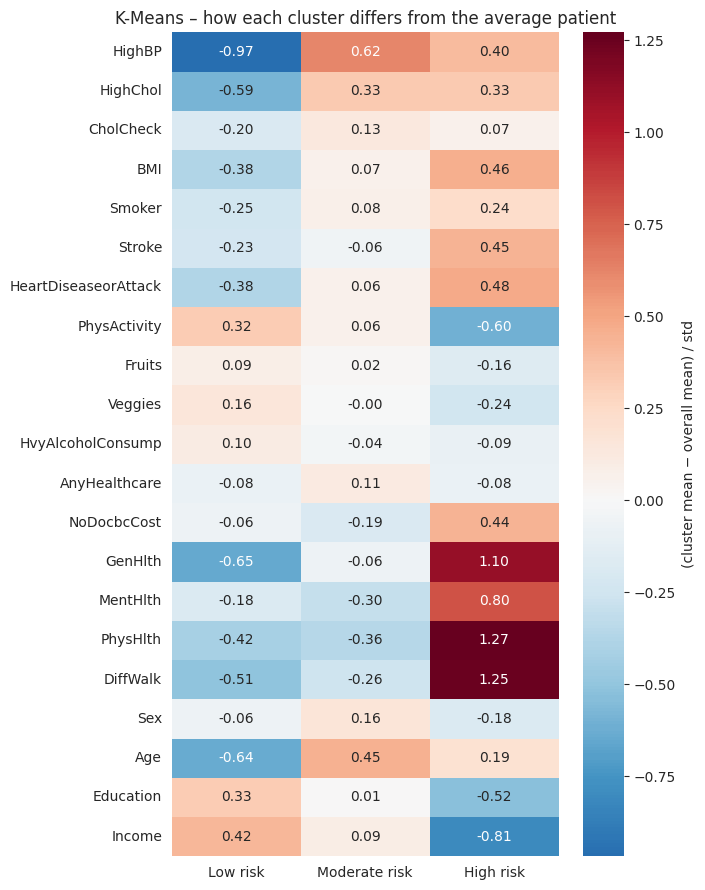

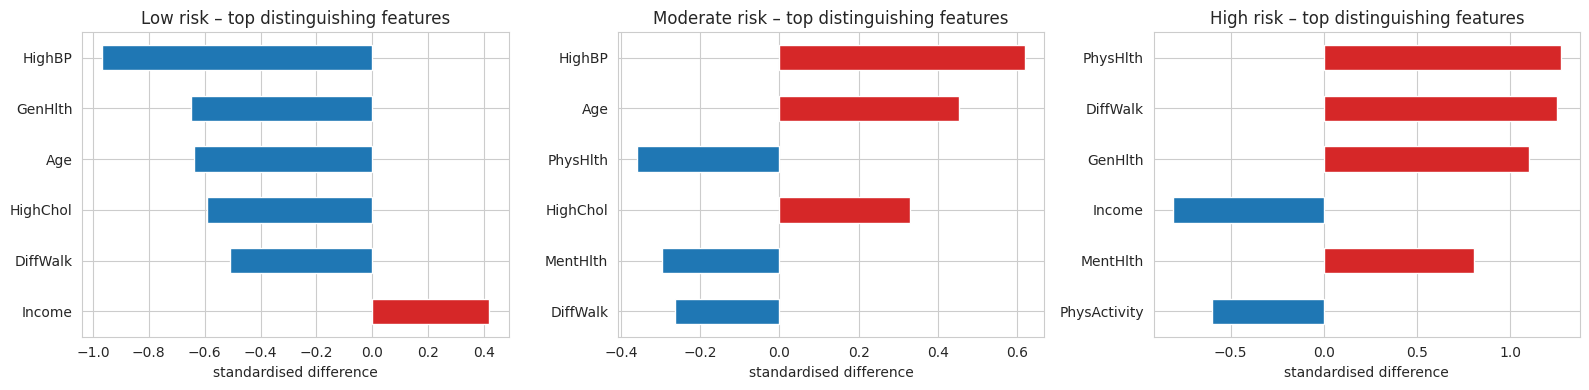

In [20]:
imp = km_profile["importance"].rename(columns=RISK_NAMES)[["Low risk", "Moderate risk", "High risk"]]

fig, ax = plt.subplots(figsize=(7, 9))
sns.heatmap(imp, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            cbar_kws={"label": "(cluster mean − overall mean) / std"})
ax.set(title="K-Means – how each cluster differs from the average patient")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, seg in zip(axes, imp.columns):
    top = imp[seg].reindex(imp[seg].abs().sort_values(ascending=False).index).head(6)
    top.plot(kind="barh", ax=ax, color=["tab:red" if v > 0 else "tab:blue" for v in top])
    ax.set(title=f"{seg} – top distinguishing features", xlabel="standardised difference")
    ax.invert_yaxis()
plt.tight_layout(); plt.show()

### 6.4 Cluster profiles
_Scales: `GenHlth` 1 = excellent … 5 = poor; `MentHlth` / `PhysHlth` = bad days in the last 30; `Age` 13 categories (7 ≈ 50–54, 9 ≈ 60–64, 10 ≈ 65–69); `Income` 1–8._

| Segment | Size | Diabetic | What characterises it | Meaning for the advice system |
|---|---|---|---|---|
| **Low risk** | 36% | 20% | Youngest group (Age ≈ 6.8), only 9% high blood pressure and 24% high cholesterol, best general health (GenHlth ≈ 2.2), most physically active (84%), highest income | Routine screening and preventive lifestyle advice; lowest priority |
| **Moderate risk** | 41% | 63% | Oldest group (Age ≈ 9.9), 88% high blood pressure and 70% high cholesterol, but good physical and mental health (≈ 2 bad days/month) and few mobility problems | "Silent" metabolic risk: patients feel well but have cardiovascular risk factors; priority for regular blood-sugar testing and BP/cholesterol management |
| **High risk** | 23% | 76% | Poor general health (GenHlth ≈ 4.1), ≈ 19 bad physical-health days and ≈ 10 bad mental-health days per month, 80% difficulty walking, lowest physical activity (42%) and income, highest heart disease (32%) and stroke (17%) | Highest priority: specialist referral and care coordination; cost barriers (22% skipped a doctor because of cost) should be considered |

**Key insight:** the label was never used, yet the clusters separate diabetes rates from 20% to 76%. The Moderate and High groups are both high-risk but for **different reasons**: one is cardiovascular risk in patients who feel healthy, the other is poor overall health and limited mobility. This difference helps choose the *type* of action, not only the priority.

### 6.5 Cluster descriptions for the GenAI team (Part B) and dashboard (Part C)
These texts are used in the `{cluster_profile}` placeholder of the prompt templates. They are saved to `cluster_profiles.json`, and every train patient with its segment is saved to `train_with_clusters.csv`.

In [21]:
import json

CLUSTER_PROFILES = {
    "Low risk": "Low-risk group (about 20% diabetic): younger patients with mostly normal blood pressure "
                "and cholesterol, good general health, physically active and with higher income.",
    "Moderate risk": "Moderate-risk group (about 63% diabetic): older patients with high blood pressure and "
                     "high cholesterol who still report good physical and mental health and few mobility problems.",
    "High risk": "High-risk group (about 76% diabetic): patients with poor general health, many days of poor "
                 "physical and mental health, difficulty walking, low physical activity, lower income and the "
                 "highest rates of heart disease and stroke.",
}

export = {str(cid): {"segment": seg,
                     "description": CLUSTER_PROFILES[seg],
                     "size_pct": float(km_profile["summary"].loc[cid, "size %"]),
                     "diabetic_pct": float(km_profile["summary"].loc[cid, "diabetic %"])}
          for cid, seg in RISK_NAMES.items()}

with open("cluster_profiles.json", "w") as f:
    json.dump(export, f, indent=2)

X_train.assign(cluster=km_labels,
               segment=pd.Series(km_labels).map(RISK_NAMES).values,
               Diabetes_binary=y_train).to_csv("train_with_clusters.csv", index=False)

pd.DataFrame(export).T

,segment,description,size_pct,diabetic_pct
1,Low risk,Low-risk group (about 20% diabetic): younger p...,35.8,20.3
0,Moderate risk,Moderate-risk group (about 63% diabetic): olde...,40.9,63.4
2,High risk,High-risk group (about 76% diabetic): patients...,23.3,75.8


## 7. Integration Strategy (Deema)
### 7.1 Cluster label as an extra feature for the Phase 1 model
The clustering model was fitted on the **train split only**; test patients are only assigned with `predict()`.
This avoids leakage — fitting on all the data would let test patients shape the clusters and make the "after" result look better than it really is.
Predictions use the **full** train and test splits (not the 10,000-row sample).

In [22]:
from sklearn.base import clone
from xgboost import XGBClassifier
from sklearn.metrics import recall_score, f1_score, accuracy_score, roc_auc_score

# Best Phase 1 model: tuned XGBoost (same hyperparameters as Phase1_Supervised_Learning.ipynb, trained on unscaled features)
BEST_PHASE1_MODEL = XGBClassifier(learning_rate=0.05, max_depth=5, n_estimators=200)

CLUSTER_MODEL = kmeans   # K-Means chosen as the final algorithm in Section 5

def add_cluster_feature(X_df, X_scaled_arr):
    """Append one-hot cluster membership to the original features."""
    labels = CLUSTER_MODEL.predict(X_scaled_arr)
    onehot = pd.get_dummies(pd.Categorical(labels, categories=range(CLUSTER_MODEL.n_components
                            if hasattr(CLUSTER_MODEL, "n_components") else CLUSTER_MODEL.n_clusters)),
                            prefix="cluster").astype(int)
    return pd.concat([X_df.reset_index(drop=True), onehot], axis=1)

X_train_c = add_cluster_feature(X_train, X_train_s)
X_test_c  = add_cluster_feature(X_test,  X_test_s)

rows = []
for name, Xtr, Xte in [("Without cluster", X_train, X_test), ("With cluster", X_train_c, X_test_c)]:
    m = clone(BEST_PHASE1_MODEL).fit(Xtr, y_train)
    pred, proba = m.predict(Xte), m.predict_proba(Xte)[:, 1]
    rows.append({"Setup": name, "Accuracy": accuracy_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba)})
pd.DataFrame(rows).set_index("Setup").round(4)

,Accuracy,Recall,F1,ROC-AUC
Setup,,,,
Without cluster,0.7504,0.8041,0.7660,0.8241
With cluster,0.7495,0.8056,0.7657,0.8238


The "Without cluster" row should match the XGBoost row in `Supervised_Learning/evaluation_results/model_comparison.csv` (F1 ≈ 0.766, ROC-AUC ≈ 0.824).

**Interpretation:** Adding the cluster label made **almost no difference**: Recall increased slightly (0.8041 → 0.8056), while Accuracy, F1 and ROC-AUC changed by less than 0.001 — within normal random variation.

This is expected for three reasons:
- **The cluster is built from the same 21 features** the model already uses, so it adds no new information — it is a summary of existing features.
- **XGBoost already learns feature combinations** (e.g. HighBP + poor GenHlth + older Age) through its tree splits, so it captures these groups on its own.
- **The clusters are not sharply separated** (Silhouette 0.073), so the label is a coarse summary of patient risk.

**Decision:** the cluster label is **not added** to the prediction model. Clustering is used instead where it adds real value — as a **patient risk segment** shown in the dashboard and as **context for GenAI explanations** (Section 7.2).

### 7.2 Cluster profile as context for GenAI (Part B)
Each patient is assigned to a cluster with `assign_cluster()` (see `cluster_interface.py`), which returns the cluster ID and a short profile description, for example:
*"High-risk group: older patients with high blood pressure and cholesterol, poor general health and difficulty walking."*

This description is passed to the GenAI prompt templates (Part B) through the `{cluster_profile}` placeholder, so the generated executive briefing explains **which patient segment** the person belongs to — not only the prediction. This directly supports the **Personalization** criterion ("Does it reflect the user's context or cluster?").

In the dashboard (Part C), the cluster is shown as a **risk segment** next to the prediction, together with the size and diabetes rate of that segment.

### 7.3 Exporting the model for the pipeline & dashboard

In [23]:
# ⚠️ Run this ONLY after the final algorithm is chosen together in Section 5
FINAL_MODEL = CLUSTER_MODEL   # KMeans and GaussianMixture both support .predict(), so assign_cluster works for either

joblib.dump({"scaler": scaler, "model": FINAL_MODEL, "feature_names": feature_names},
            "cluster_model.joblib")
print("Saved cluster_model.joblib")

Saved cluster_model.joblib


## 8. Challenges & Limitations
- **Binary features:** K-Means and GMM assume continuous data; most features here are 0/1, so distances and Gaussian assumptions are only approximate.
  K-Modes / K-Prototypes are designed for categorical data and are a possible improvement.
- **Balanced (undersampled) dataset:** the 50/50 file does not reflect the real diabetes prevalence, so cluster sizes and diabetes rates per cluster do not match the real population.
- **Sampling for metrics:** Silhouette and Davies-Bouldin are computed on a 10,000-row sample for speed.
- **t-SNE:** distances and cluster sizes in t-SNE plots are not meaningful — it is used only to visualise separation.
- **Choosing k for GMM (Dalia):** the BIC kept decreasing up to k = 10 instead of reaching a minimum, because GMM can always increase the likelihood by isolating groups where a binary feature is constant. k had to be chosen using the biggest BIC drop, cluster sizes and the comparison with K-Means instead.
- **GMM on binary data (Dalia):** without `reg_covar`, GMM fails with singular covariance matrices (zero variance in clusters where a binary feature is always 0 or 1). Even with it, the clusters are driven by these constant features and membership probabilities are ≈ 1.0, so GMM's soft-clustering advantage is lost.
- **Misleading metrics (Dalia):** GMM had a better Silhouette and BCubed Recall, but only because of one giant cluster (82% of patients). Metrics had to be read together with cluster sizes and domain meaning, not on their own.
- **Standardising rare binary features:** after `StandardScaler`, rare values get very large z-scores (e.g. `CholCheck` = 0 → z ≈ −5, `Stroke` = 1 → z ≈ +4), so rare binary features influence the distance more than their real importance.
- **Arbitrary cluster numbers (Dalia):** K-Means numbering has no meaning and can change with the data or seed, so clusters were renamed by diabetes rate (Section 6.2).
- **Choosing k (Deema):** the Elbow curve had no clear elbow and the Silhouette score preferred k = 2, which only splits healthy vs unhealthy patients. We had to balance the metrics against domain meaning, and chose k = 3 because it gives clear low / moderate / high risk groups.
- **Fair integration experiment (Deema):** to avoid data leakage, the scaler and the clustering model were fitted on the Phase 1 train split only, and the same split was reused so the before/after comparison with XGBoost is fair.